# ADY201m Assignment – Cardiovascular Disease Analysis
**Thay thế IBM Db2 bằng SQLite (SQL chạy local)** – các câu truy vấn SQL giữ nguyên ý nghĩa như đề bài.

Cấu trúc: I. Tạo DB & nạp dữ liệu → II. Truy vấn SQL (10 task) → Xuất CSV → III. Phân tích dữ liệu & mô hình (OSEMN).

## I. Tạo database SQLite và nạp dữ liệu (thay cho Db2 on Cloud)

In [1]:
import sqlite3
import pandas as pd

CSV_FILE = "cardio_train_raw.csv"   # đổi tên nếu file của bạn khác
DB_FILE  = "cardio.db"

raw = pd.read_csv(CSV_FILE, sep=";")      # file gốc dùng dấu ; làm phân cách
raw.columns = [c.upper() for c in raw.columns]   # giống Db2: ID, AGE, GENDER...
print(raw.shape)
raw.head()

(70000, 13)


,ID,AGE,GENDER,HEIGHT,WEIGHT,AP_HI,AP_LO,CHOLESTEROL,GLUC,SMOKE,ALCO,ACTIVE,CARDIO
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [2]:
conn = sqlite3.connect(DB_FILE)
raw.to_sql("CARDIO_TRAIN", conn, if_exists="replace", index=False)   # tạo bảng + nạp 70.000 dòng
conn.commit()
print("Connected to SQLite database:", DB_FILE)
print("SQLite version:", sqlite3.sqlite_version)

Connected to SQLite database: cardio.db
SQLite version: 3.50.4


In [3]:
cur = conn.cursor()
cur.execute("PRAGMA table_info(CARDIO_TRAIN)")
for col in cur.fetchall():
    print(col[1], col[2])

ID INTEGER
AGE INTEGER
GENDER INTEGER
HEIGHT INTEGER
WEIGHT REAL
AP_HI INTEGER
AP_LO INTEGER
CHOLESTEROL INTEGER
GLUC INTEGER
SMOKE INTEGER
ALCO INTEGER
ACTIVE INTEGER
CARDIO INTEGER


## II. Truy vấn SQL

### Task 1: Đếm số dòng

In [4]:
cur.execute("SELECT COUNT(ID) FROM CARDIO_TRAIN")
print(cur.fetchone())

(70000,)


### Task 2: Đếm số ca mắc bệnh tim mạch

In [5]:
cur.execute("SELECT COUNT(CARDIO) FROM CARDIO_TRAIN WHERE CARDIO=1")
print(cur.fetchone())

(34979,)


### Task 3: Số nữ và nam (GENDER=1 và GENDER=2)

In [6]:
for g in (1, 2):
    cur.execute("SELECT COUNT(GENDER) FROM CARDIO_TRAIN WHERE GENDER=?", (g,))
    print("GENDER =", g, ":", cur.fetchone()[0])

GENDER = 1 : 45530
GENDER = 2 : 24470


### Chuyển tuổi từ ngày sang năm (cần cho Task 7)

In [7]:
# Chỉ chạy 1 LẦN. Chia nguyên (integer division) như bản Db2.
cur.execute("SELECT MAX(AGE) FROM CARDIO_TRAIN")
if cur.fetchone()[0] > 1000:      # tránh chia 2 lần nếu lỡ chạy lại
    cur.execute("UPDATE CARDIO_TRAIN SET AGE = AGE/365")
    conn.commit()
pd.read_sql("SELECT * FROM CARDIO_TRAIN LIMIT 5", conn)

,ID,AGE,GENDER,HEIGHT,WEIGHT,AP_HI,AP_LO,CHOLESTEROL,GLUC,SMOKE,ALCO,ACTIVE,CARDIO
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0


In [8]:
def run_task(query, col):
    """Chạy query, in từng dòng và đếm số ca CARDIO=1 trong 10 dòng."""
    cur.execute(query)
    rows = cur.fetchall()
    count = 0
    for r in rows:
        print(f" {col}: {float(r[0])} CARDIO: {r[1]}")
        count += int(r[1] == 1)
    print(f"There are {count}/{len(rows)} cases got illness  ->  {count/len(rows)*100:.0f}%")
    return count

### Task 4: 10 người có AP_HI cao nhất – bao nhiêu % mắc bệnh

In [9]:
run_task("SELECT AP_HI, CARDIO FROM CARDIO_TRAIN ORDER BY AP_HI DESC LIMIT 10", "AP_HI")

 AP_HI: 16020.0 CARDIO: 1
 AP_HI: 14020.0 CARDIO: 1
 AP_HI: 14020.0 CARDIO: 1
 AP_HI: 14020.0 CARDIO: 1
 AP_HI: 14020.0 CARDIO: 0
 AP_HI: 13010.0 CARDIO: 1
 AP_HI: 13010.0 CARDIO: 0
 AP_HI: 11500.0 CARDIO: 1
 AP_HI: 11020.0 CARDIO: 1
 AP_HI: 2000.0 CARDIO: 1
There are 8/10 cases got illness  ->  80%


8

### Task 5: 10 người có cân nặng lớn hơn trung bình (sắp xếp giảm dần)

In [10]:
run_task("""SELECT WEIGHT, CARDIO FROM CARDIO_TRAIN
            WHERE WEIGHT > (SELECT AVG(WEIGHT) FROM CARDIO_TRAIN)
            ORDER BY WEIGHT DESC LIMIT 10""", "WEIGHT")

 WEIGHT: 200.0 CARDIO: 0
 WEIGHT: 200.0 CARDIO: 1
 WEIGHT: 183.0 CARDIO: 1
 WEIGHT: 181.0 CARDIO: 1
 WEIGHT: 180.0 CARDIO: 1
 WEIGHT: 180.0 CARDIO: 1
 WEIGHT: 180.0 CARDIO: 1
 WEIGHT: 180.0 CARDIO: 1
 WEIGHT: 178.0 CARDIO: 0
 WEIGHT: 178.0 CARDIO: 1
There are 8/10 cases got illness  ->  80%


8

### Task 6: 10 người có GLUC > 1

In [11]:
run_task("SELECT GLUC, CARDIO FROM CARDIO_TRAIN WHERE GLUC > 1 ORDER BY ID LIMIT 10", "GLUC")

 GLUC: 2.0 CARDIO: 0
 GLUC: 3.0 CARDIO: 1
 GLUC: 3.0 CARDIO: 0
 GLUC: 2.0 CARDIO: 1
 GLUC: 3.0 CARDIO: 0
 GLUC: 3.0 CARDIO: 1
 GLUC: 2.0 CARDIO: 0
 GLUC: 2.0 CARDIO: 1
 GLUC: 2.0 CARDIO: 0
 GLUC: 2.0 CARDIO: 1
There are 5/10 cases got illness  ->  50%


5

### Task 7: 10 người lớn tuổi nhất

In [12]:
run_task("SELECT AGE, CARDIO FROM CARDIO_TRAIN ORDER BY AGE DESC, ID LIMIT 10", "AGE")

 AGE: 64.0 CARDIO: 0
 AGE: 64.0 CARDIO: 1
 AGE: 64.0 CARDIO: 1
 AGE: 64.0 CARDIO: 0
 AGE: 64.0 CARDIO: 1
 AGE: 64.0 CARDIO: 1
 AGE: 64.0 CARDIO: 1
 AGE: 64.0 CARDIO: 0
 AGE: 64.0 CARDIO: 1
 AGE: 64.0 CARDIO: 1
There are 7/10 cases got illness  ->  70%


7

### Task 8: 10 người có CHOLESTEROL = 3

In [13]:
run_task("SELECT CHOLESTEROL, CARDIO FROM CARDIO_TRAIN WHERE CHOLESTEROL=3 ORDER BY ID LIMIT 10", "CHOLESTEROL")

 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 0
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
 CHOLESTEROL: 3.0 CARDIO: 1
There are 9/10 cases got illness  ->  90%


9

### Task 9: 10 người hút thuốc

In [14]:
run_task("SELECT SMOKE, CARDIO FROM CARDIO_TRAIN WHERE SMOKE=1 ORDER BY ID LIMIT 10", "SMOKE")

 SMOKE: 1.0 CARDIO: 0
 SMOKE: 1.0 CARDIO: 0
 SMOKE: 1.0 CARDIO: 1
 SMOKE: 1.0 CARDIO: 1
 SMOKE: 1.0 CARDIO: 1
 SMOKE: 1.0 CARDIO: 1
 SMOKE: 1.0 CARDIO: 0
 SMOKE: 1.0 CARDIO: 1
 SMOKE: 1.0 CARDIO: 1
 SMOKE: 1.0 CARDIO: 1
There are 7/10 cases got illness  ->  70%


7

### Task 10: 10 người có tập thể dục

In [15]:
run_task("SELECT ACTIVE, CARDIO FROM CARDIO_TRAIN WHERE ACTIVE=1 ORDER BY ID LIMIT 10", "ACTIVE")

 ACTIVE: 1.0 CARDIO: 0
 ACTIVE: 1.0 CARDIO: 1
 ACTIVE: 1.0 CARDIO: 1
 ACTIVE: 1.0 CARDIO: 0
 ACTIVE: 1.0 CARDIO: 1
 ACTIVE: 1.0 CARDIO: 0
 ACTIVE: 1.0 CARDIO: 0
 ACTIVE: 1.0 CARDIO: 0
 ACTIVE: 1.0 CARDIO: 0
 ACTIVE: 1.0 CARDIO: 0
There are 3/10 cases got illness  ->  30%


3

> **Lưu ý:** mỗi truy vấn chỉ lấy 10 dòng nên tỉ lệ % chỉ mang tính minh hoạ, không đại diện cho toàn bộ 70.000 người.
> Task 6, 8, 9, 10 mình thêm `ORDER BY ID` để kết quả cố định, lặp lại được.

## Lưu bảng ra CSV để phân tích offline và đóng kết nối

In [16]:
df = pd.read_sql("SELECT * FROM CARDIO_TRAIN", conn)
df.to_csv("CARDIO_TRAIN.csv", index=False)
conn.close()
print("Saved CARDIO_TRAIN.csv, connection closed.", df.shape)

Saved CARDIO_TRAIN.csv, connection closed. (70000, 13)


## III. Phân tích dữ liệu với Python (OSEMN)

### Obtain – đọc CSV và kiểm tra

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("CARDIO_TRAIN.csv")
df.head(10)

,ID,AGE,GENDER,HEIGHT,WEIGHT,AP_HI,AP_LO,CHOLESTEROL,GLUC,SMOKE,ALCO,ACTIVE,CARDIO
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0
5,8,60,1,151,67.0,120,80,2,2,0,0,0,0
6,9,60,1,157,93.0,130,80,3,1,0,0,1,0
7,12,61,2,178,95.0,130,90,3,3,0,0,1,1
8,13,48,1,158,71.0,110,70,1,1,0,0,1,0
9,14,54,1,164,68.0,110,60,1,1,0,0,0,0


In [18]:
df.describe()

,ID,AGE,GENDER,HEIGHT,WEIGHT,AP_HI,AP_LO,CHOLESTEROL,GLUC,SMOKE,ALCO,ACTIVE,CARDIO
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,52.840671,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,6.766774,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,29.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,53.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,64.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [19]:
print(df.isnull().sum())
print("Tổng giá trị null:", df.isnull().sum().sum())

ID             0
AGE            0
GENDER         0
HEIGHT         0
WEIGHT         0
AP_HI          0
AP_LO          0
CHOLESTEROL    0
GLUC           0
SMOKE          0
ALCO           0
ACTIVE         0
CARDIO         0
dtype: int64
Tổng giá trị null: 0


**Nhận xét:** không có giá trị null nên không cần điền giá trị thiếu. Tuy nhiên `AP_HI`, `AP_LO` có giá trị âm / cực lớn (vô lý về y khoa) → cần xử lý outlier.

### Explore – tương quan và biểu đồ

In [20]:
corr_target = df.corr()["CARDIO"].sort_values(ascending=False)
corr_target

CARDIO         1.000000
AGE            0.237985
CHOLESTEROL    0.221147
WEIGHT         0.181660
GLUC           0.089307
AP_LO          0.065719
AP_HI          0.054475
GENDER         0.008109
ID             0.003799
ALCO          -0.007330
HEIGHT        -0.010821
SMOKE         -0.015486
ACTIVE        -0.035653
Name: CARDIO, dtype: float64

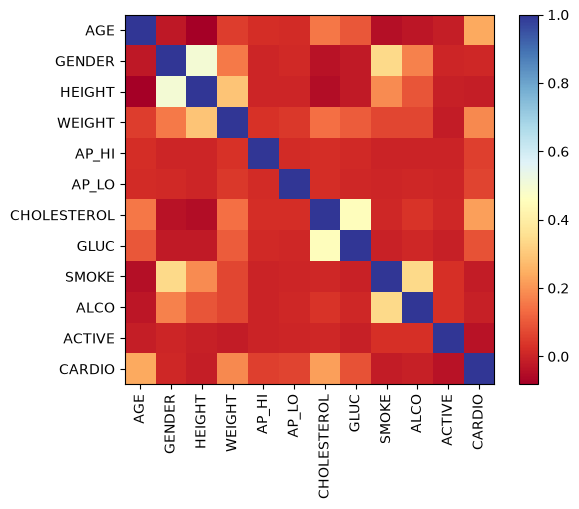

In [21]:
cols = ['AGE','GENDER','HEIGHT','WEIGHT','AP_HI','AP_LO','CHOLESTEROL','GLUC','SMOKE','ALCO','ACTIVE','CARDIO']
corr = df[cols].corr()
plt.imshow(corr, cmap="RdYlBu")
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.index)
plt.show()

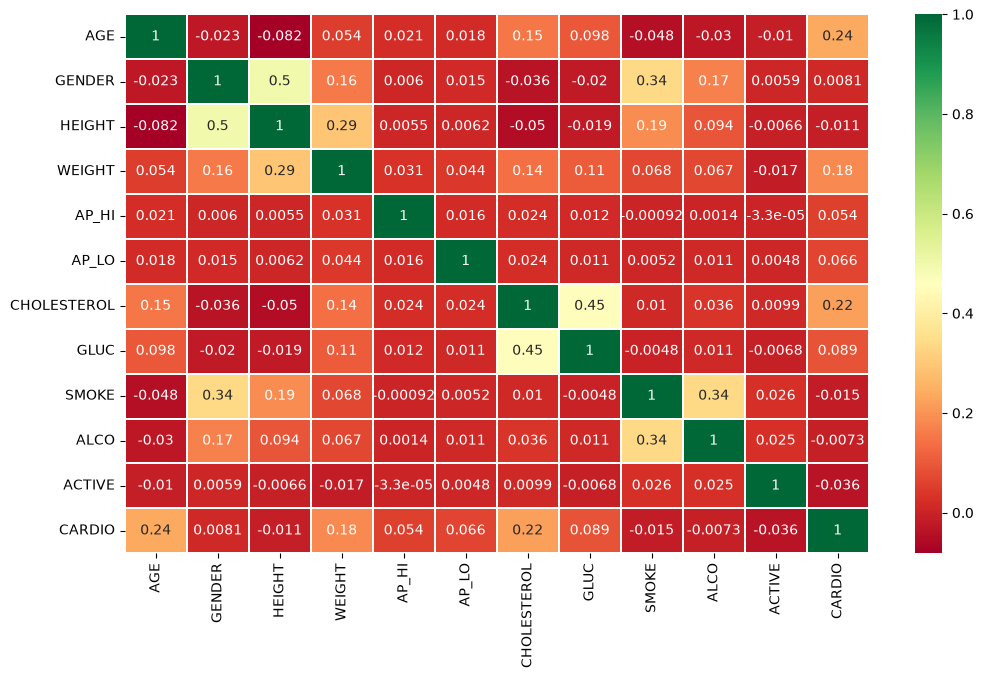

In [22]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(corr, cmap='RdYlGn', linewidths=0.30, annot=True, ax=ax)
plt.show()

**Nhận xét:** AGE, CHOLESTEROL và WEIGHT có tương quan dương mạnh nhất với CARDIO. Cần kiểm định thống kê để xác nhận.

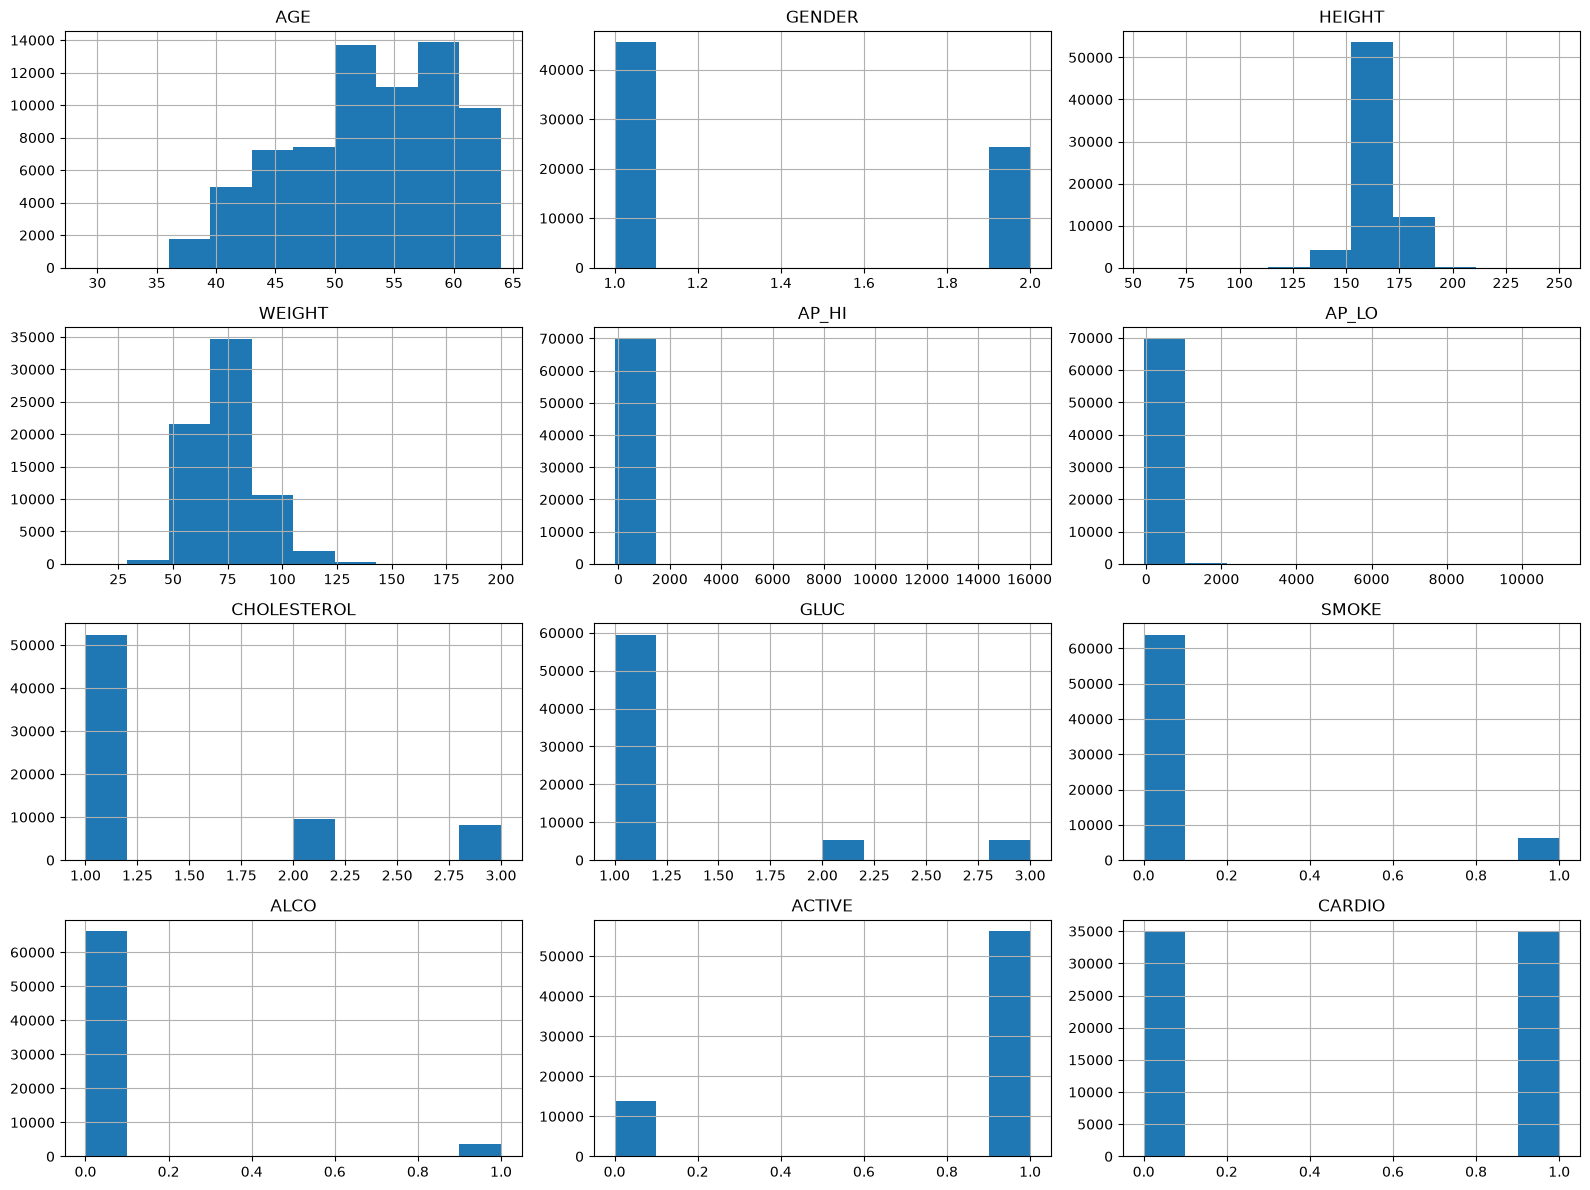

In [23]:
df[cols].hist(figsize=[16, 12])
plt.tight_layout()
plt.show()

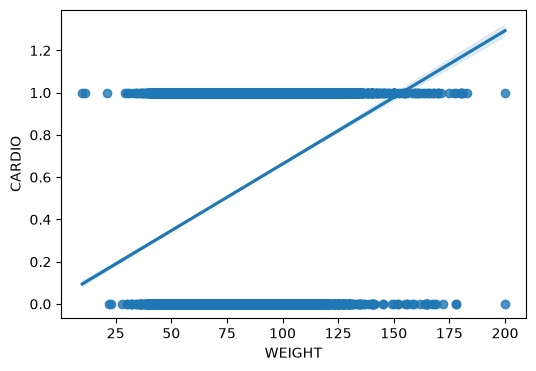

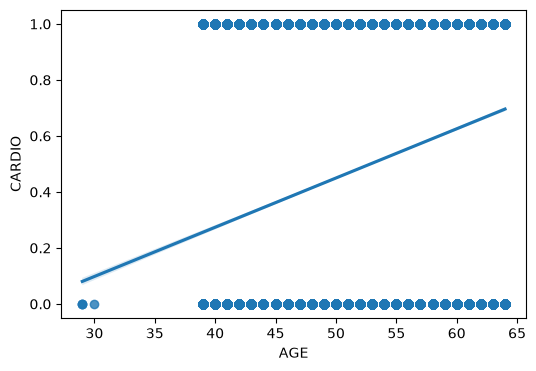

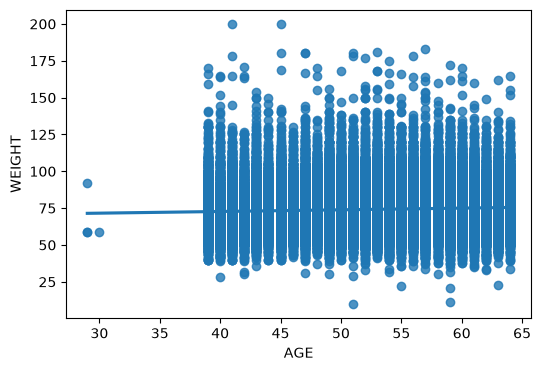

In [24]:
for x, y in [("WEIGHT","CARDIO"), ("AGE","CARDIO"), ("AGE","WEIGHT")]:
    plt.figure(figsize=(6, 4))
    sns.regplot(x=x, y=y, data=df)
    plt.show()

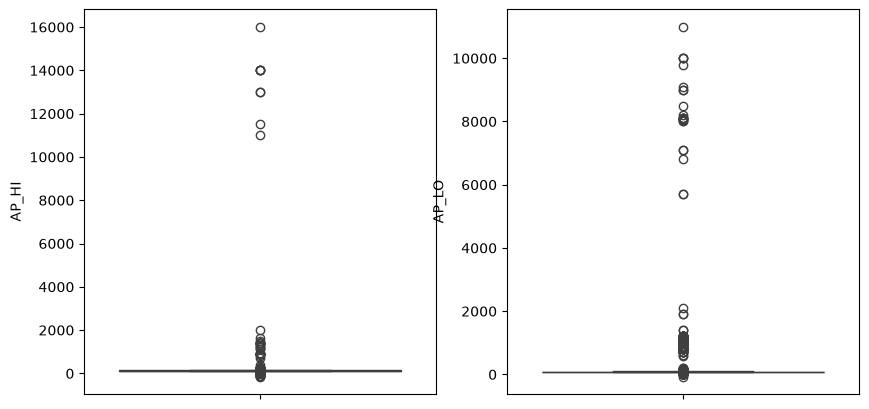

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.boxplot(y="AP_HI", data=df, ax=axes[0])
sns.boxplot(y="AP_LO", data=df, ax=axes[1])
plt.show()

**Nhận xét:** AP_HI và AP_LO có rất nhiều outlier → thay thế theo quy tắc IQR ở bước Scrub.

### Scrub – xử lý outlier (IQR)

In [26]:
def cap_outliers_iqr(frame, col):
    q1, q3 = frame[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper, lower = q3 + 1.5*iqr, q1 - 1.5*iqr
    print(f"{col}: maximum = {upper}, minimum = {lower}")
    frame.loc[frame[col] > upper, col] = upper
    frame.loc[frame[col] < lower, col] = lower

cap_outliers_iqr(df, "AP_HI")
cap_outliers_iqr(df, "AP_LO")

AP_HI: maximum = 170.0, minimum = 90.0
AP_LO: maximum = 105.0, minimum = 65.0


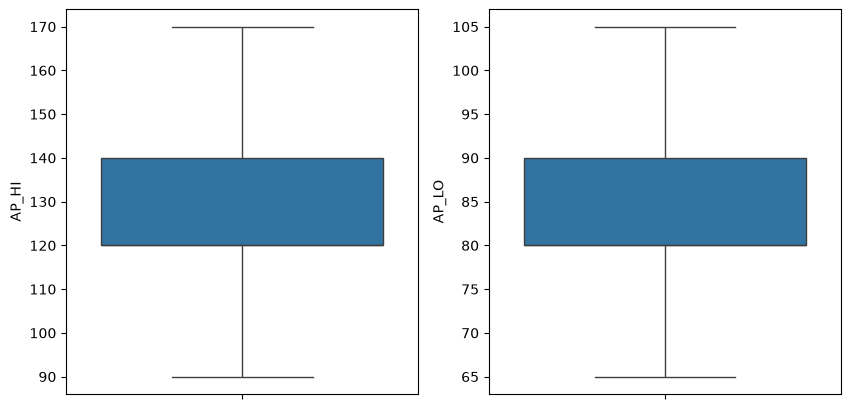

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.boxplot(y="AP_HI", data=df, ax=axes[0])
sns.boxplot(y="AP_LO", data=df, ax=axes[1])
plt.show()

### Kiểm định thống kê

**CHOLESTEROL vs CARDIO** – H0: cholesterol không liên quan bệnh (One-way ANOVA)

In [28]:
from scipy.stats import f_oneway
g1 = df[df.CHOLESTEROL==1].CARDIO
g2 = df[df.CHOLESTEROL==2].CARDIO
g3 = df[df.CHOLESTEROL==3].CARDIO
f_stat, p = f_oneway(g1, g2, g3)
print(f"F_Statistic: {f_stat}, P-Value: {p}")

F_Statistic: 1799.6607856699582, P-Value: 0.0


**Kết luận:** p-value < 0.05 → bác bỏ H0, cholesterol có liên quan đến bệnh tim mạch.

**AGE vs CARDIO** – H0: tuổi không liên quan bệnh (t-test giữa nhóm trẻ / nhóm lớn tuổi)

In [29]:
from scipy.stats import levene, ttest_ind
lower_age = df[df.AGE <  df.AGE.mean()].CARDIO
higher_age = df[df.AGE >= df.AGE.mean()].CARDIO
f_stat, p = levene(lower_age, higher_age, center='mean')
print(f"Levene: F={f_stat}, P={p}")
t_stat, p_t = ttest_ind(lower_age, higher_age, equal_var=(p > 0.05))
print(f"T-Test: t={t_stat}, P={p_t}")

Levene: F=133.98315419526423, P=5.880069082433678e-31
T-Test: t=-52.51350890203988, P=0.0


**Kết luận:** p-value < 0.05 → bác bỏ H0, nhóm lớn tuổi có tỉ lệ bệnh khác nhóm trẻ.

**WEIGHT vs CARDIO** – H0: cân nặng không liên quan bệnh (Pearson)

In [30]:
from scipy.stats import pearsonr
coeff, p = pearsonr(df.WEIGHT, df.CARDIO)
print("coeff:", coeff, "p_value:", p)

coeff: 0.1816595617986251 p_value: 0.0


**Kết luận:** p-value < 0.05 → bác bỏ H0, cân nặng có quan hệ (dương, yếu–vừa) với bệnh.

**ALCOHOL vs CARDIO** – H0: uống rượu không liên quan bệnh (Chi-square)

In [31]:
from scipy.stats import chi2_contingency
cont = pd.crosstab(df.ALCO, df.CARDIO)
chi2, p, dof, expected = chi2_contingency(cont, correction=True)
print("chi2:", chi2, "p_value:", p, "dof:", dof)
print(cont)

chi2: 3.696547466479263 p_value: 0.05452518218322108 dof: 1
CARDIO      0      1
ALCO                
0       33080  33156
1        1941   1823


**Kết luận:** p-value ≈ 0.0545 > 0.05 → không đủ bằng chứng bác bỏ H0 (ở mức 5%).

### Mô hình OLS (statsmodels)

In [32]:
import statsmodels.api as sm
X_ols = sm.add_constant(df[['AGE','GENDER','HEIGHT','WEIGHT','AP_HI','AP_LO','CHOLESTEROL','GLUC','SMOKE','ALCO','ACTIVE']])
y_ols = df['CARDIO']
model = sm.OLS(y_ols, X_ols).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 CARDIO   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     1954.
Date:                Thu, 08 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:21:27   Log-Likelihood:                -41431.
No. Observations:               70000   AIC:                         8.289e+04
Df Residuals:                   69988   BIC:                         8.300e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.6708      0.042    -39.948      0.000      -1.753      -1.589
AGE             0.0101      0.000     40.131      0.000       0.010       0.011
GENDER         -0.0041      0.004     -0.979      0.328      -0.012       0.004
HEIGHT         -0.0008      0.000     -3.229      0.001      -0.001      -0.000
WEIGHT          0.0021      0.000     16.542      0.000       0.002       0.002
AP_HI           0.0096      0.000     64.319      0.000       0.009       0.010
AP_LO           0.0040      0.000     14.993      0.000       0.003       0.005
CHOLESTEROL     0.0941      0.003     33.686      0.000       0.089       0.100
GLUC           -0.0207      0.003     -6.381      0.000      -0.027      -0.014
SMOKE          -0.0257      0.007     -3.953      0.000      -0.039      -0.013
ALCO           -0.0379      0.008     -4.840      0.000      -0.053      -0.023
ACTIVE         -0.0437      0.004    -10.487      0.000      -0.052      -0.036
==============================================================================
Omnibus:                    26450.215   Durbin-Watson:                   1.981
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3466.466
Skew:                           0.049   Prob(JB):                         0.00
Kurtosis:                       1.914   Cond. No.                     6.11e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.11e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Model – chuẩn hoá, chia dữ liệu, huấn luyện

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

num_cols = ['AGE','HEIGHT','WEIGHT','AP_HI','AP_LO']
cat_cols = ['GENDER','CHOLESTEROL','GLUC','SMOKE','ALCO','ACTIVE']
y = df['CARDIO'].values

# Chia train/test TRƯỚC, rồi mới fit scaler trên tập train (tránh data leakage)
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.3, random_state=42)
scaler = StandardScaler().fit(df.loc[idx_train, num_cols])

def make_X(idx):
    return np.concatenate([scaler.transform(df.loc[idx, num_cols]), df.loc[idx, cat_cols].values], axis=1)

X_train, X_test = make_X(idx_train), make_X(idx_test)
y_train, y_test = y[idx_train], y[idx_test]
print(X_train.shape, X_test.shape)

(49000, 11) (21000, 11)


### Ridge Classifier

In [34]:
from sklearn.linear_model import RidgeClassifier
ridge = RidgeClassifier(alpha=0.0001).fit(X_train, y_train)
print("Ridge accuracy:", accuracy_score(y_test, ridge.predict(X_test)))

Ridge accuracy: 0.7301428571428571


### Thử các mô hình khác (fine-tuning)

In [35]:
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
                              BaggingClassifier, ExtraTreesClassifier, StackingClassifier)
from sklearn.neighbors import KNeighborsClassifier

models = {
    "RandomForest": RandomForestClassifier(random_state=0),
    "GradientBoosting": GradientBoostingClassifier(random_state=0),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=0),
    "Bagging(KNN)": BaggingClassifier(KNeighborsClassifier(), max_samples=0.5, max_features=0.5, random_state=0),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=0),
    "Stacking": StackingClassifier(
        estimators=[('ridge', RidgeClassifier()), ('knr', KNeighborsClassifier(n_neighbors=20, metric='euclidean'))],
        final_estimator=GradientBoostingClassifier(n_estimators=25, subsample=0.5, min_samples_leaf=25,
                                                   max_features=1, random_state=42)),
}
results = {"Ridge": accuracy_score(y_test, ridge.predict(X_test))}
for name, m in models.items():
    m.fit(X_train, y_train)
    results[name] = accuracy_score(y_test, m.predict(X_test))
    print(f"{name:18s} {results[name]:.4f}")

RandomForest       0.7092
GradientBoosting   0.7393
AdaBoost           0.7340
Bagging(KNN)       0.7240
ExtraTrees         0.6942
Stacking           0.7332


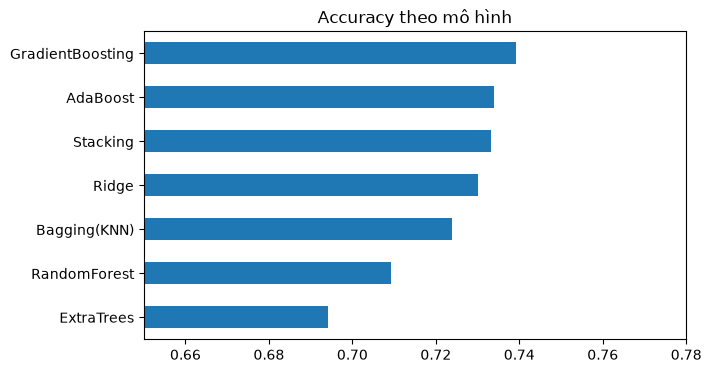

GradientBoosting    0.739286
AdaBoost            0.733952
Stacking            0.733238
Ridge               0.730143
Bagging(KNN)        0.723952
RandomForest        0.709238
ExtraTrees          0.694190
dtype: float64

In [36]:
res = pd.Series(results).sort_values(ascending=False)
res.plot(kind="barh", figsize=(7, 4), title="Accuracy theo mô hình")
plt.gca().invert_yaxis(); plt.xlim(0.65, 0.78); plt.show()
res

### Interpret – Kết luận
- Bộ dữ liệu 70.000 bệnh nhân, ~50% có bệnh tim mạch (34.979 ca), không có giá trị null nhưng có outlier huyết áp.
- Các yếu tố liên quan mạnh nhất: **tuổi, cholesterol, cân nặng, huyết áp** (đều có ý nghĩa thống kê, p < 0.05). Rượu không có ý nghĩa ở mức 5%.
- Mô hình tốt nhất đạt accuracy khoảng 73–74% (xem bảng trên); Gradient Boosting thường nhỉnh hơn Ridge.
- Hạn chế: chỉ dùng accuracy, chưa tinh chỉnh siêu tham số (GridSearch), tương quan ≠ nhân quả.